Training data shape: (4000, 784)
Testing data shape: (500, 784)


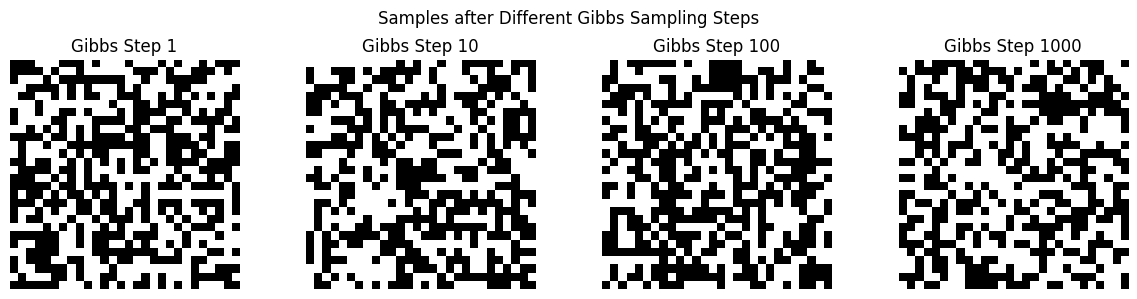


Training: CD-1
CD-1 | Epoch 1/5 | Reconstruction Error: 0.1581 | Pseudo-Log-Likelihood: -341.67
CD-1 | Epoch 2/5 | Reconstruction Error: 0.1072 | Pseudo-Log-Likelihood: -327.41
CD-1 | Epoch 3/5 | Reconstruction Error: 0.0981 | Pseudo-Log-Likelihood: -225.89
CD-1 | Epoch 4/5 | Reconstruction Error: 0.0939 | Pseudo-Log-Likelihood: -276.52
CD-1 | Epoch 5/5 | Reconstruction Error: 0.0912 | Pseudo-Log-Likelihood: -221.93

Training: CD-5
CD-5 | Epoch 1/5 | Reconstruction Error: 0.1609 | Pseudo-Log-Likelihood: -281.97
CD-5 | Epoch 2/5 | Reconstruction Error: 0.1118 | Pseudo-Log-Likelihood: -275.43
CD-5 | Epoch 3/5 | Reconstruction Error: 0.1024 | Pseudo-Log-Likelihood: -249.76
CD-5 | Epoch 4/5 | Reconstruction Error: 0.0973 | Pseudo-Log-Likelihood: -217.48
CD-5 | Epoch 5/5 | Reconstruction Error: 0.0940 | Pseudo-Log-Likelihood: -207.39

Training: CD-10
CD-10 | Epoch 1/5 | Reconstruction Error: 0.1633 | Pseudo-Log-Likelihood: -363.61
CD-10 | Epoch 2/5 | Reconstruction Error: 0.1159 | Pseudo-L

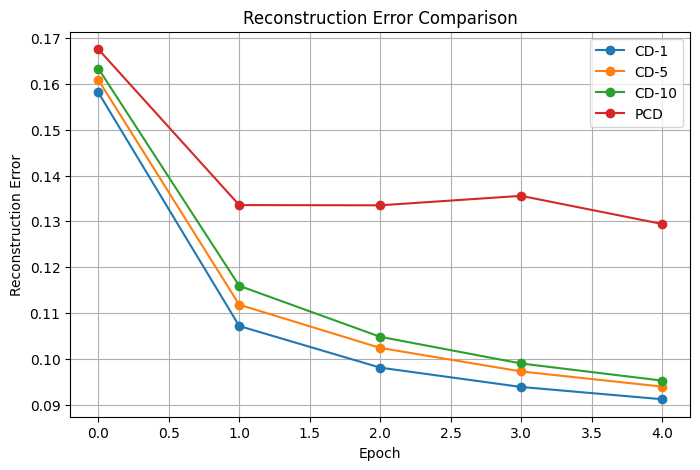

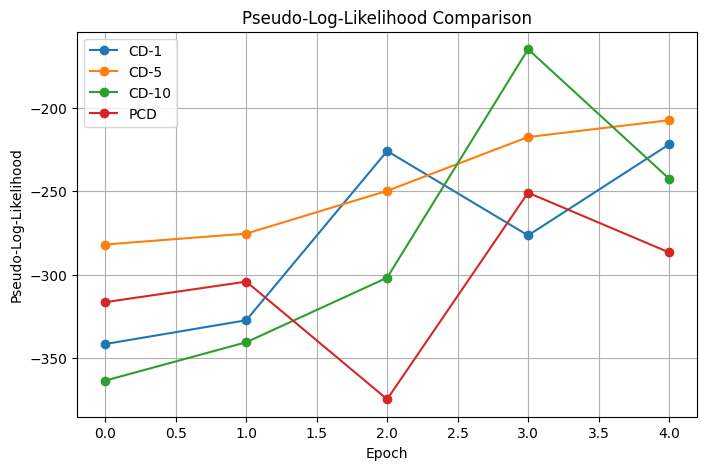

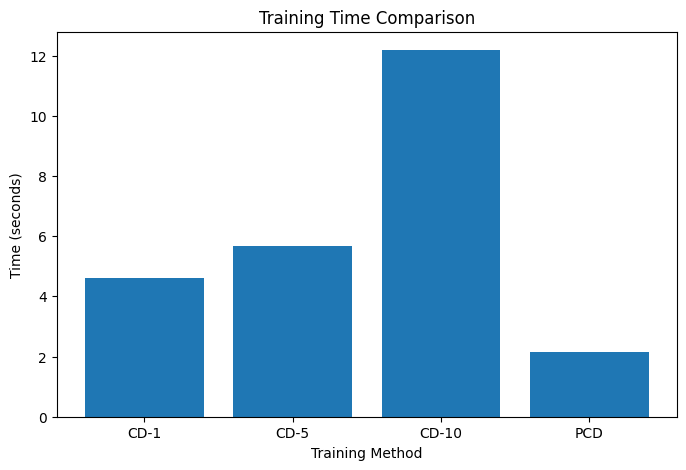

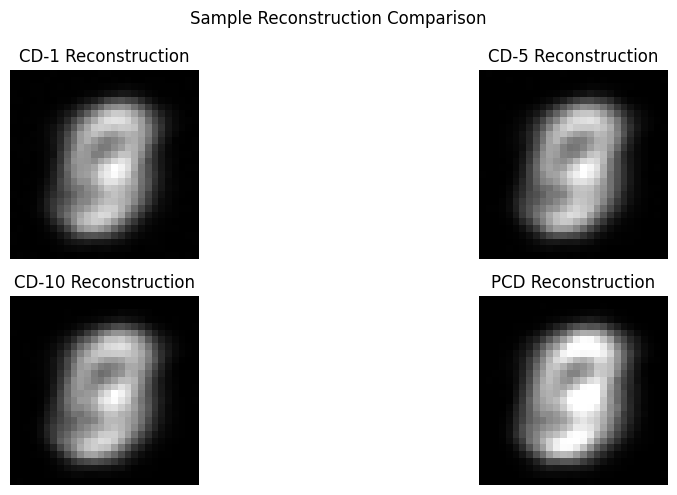


FINAL COMPARISON
---------------------------------------------------------------------------
Method       Error           PLL                  Time (sec)     
---------------------------------------------------------------------------
CD-1         0.0912          -221.93              4.60           
CD-5         0.0940          -207.39              5.66           
CD-10        0.0953          -242.41              12.18          
PCD          0.1294          -286.68              2.15           
---------------------------------------------------------------------------

Experiment 26 completed successfully!


In [30]:
# EXPERIMENT 26: GIBBS SAMPLING AND CONTRASTIVE DIVERGENCE ANALYSIS

import numpy as np
import matplotlib.pyplot as plt
import time
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# --------------------------------------------------
# 1. LOAD AND BINARIZE MNIST DATA
# --------------------------------------------------

np.random.seed(42)

(X_train, _), (X_test, _) = mnist.load_data()

X_train = X_train[:4000]
X_test = X_test[:500]

X_train = (X_train > 127).astype(np.float32).reshape(-1, 784)
X_test = (X_test > 127).astype(np.float32).reshape(-1, 784)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# --------------------------------------------------
# 2. RBM FUNCTIONS
# --------------------------------------------------

def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1 / (1 + np.exp(-x))


class RBM:
    def __init__(self, visible=784, hidden=64, lr=0.01):
        self.visible = visible
        self.hidden = hidden
        self.lr = lr

        self.W = np.random.normal(0, 0.01, (visible, hidden))
        self.v_bias = np.zeros(visible)
        self.h_bias = np.zeros(hidden)

    def hidden_prob(self, v):
        return sigmoid(v @ self.W + self.h_bias)

    def visible_prob(self, h):
        return sigmoid(h @ self.W.T + self.v_bias)

    def sample(self, prob):
        return (np.random.rand(*prob.shape) < prob).astype(np.float32)

    def gibbs(self, v, steps=1):
        for _ in range(steps):
            h_prob = self.hidden_prob(v)
            h_sample = self.sample(h_prob)
            v_prob = self.visible_prob(h_sample)
            v_sample = self.sample(v_prob)
            v = v_sample

        return v, v_prob, h_sample

    def energy(self, v, h):
        return -np.sum(v * self.v_bias, axis=1) \
               -np.sum(h * self.h_bias, axis=1) \
               -np.sum((v @ self.W) * h, axis=1)

    def free_energy(self, v):
        hidden_term = np.sum(
            np.logaddexp(0, v @ self.W + self.h_bias), axis=1
        )
        return -v @ self.v_bias - hidden_term


# --------------------------------------------------
# 3. GIBBS SAMPLING FROM RANDOM NOISE
# --------------------------------------------------

sampling_rbm = RBM()

noise = np.random.randint(0, 2, (1, 784)).astype(np.float32)

sample_steps = [1, 10, 100, 1000]
samples = []

v = noise.copy()

for step in range(1, 1001):
    v, v_prob, h_sample = sampling_rbm.gibbs(v, 1)

    if step in sample_steps:
        samples.append(v.copy())

# Display generated samples at different Gibbs steps

plt.figure(figsize=(12, 3))

for i, step in enumerate(sample_steps):
    plt.subplot(1, 4, i + 1)
    plt.imshow(samples[i][0].reshape(28, 28), cmap="gray")
    plt.title(f"Gibbs Step {step}")
    plt.axis("off")

plt.suptitle("Samples after Different Gibbs Sampling Steps")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. PSEUDO-LOG-LIKELIHOOD APPROXIMATION
# --------------------------------------------------

def pseudo_log_likelihood(rbm, data):
    # Randomly flip one pixel per sample
    flip_index = np.random.randint(0, 784, size=len(data))

    flipped = data.copy()
    flipped[np.arange(len(data)), flip_index] = \
        1 - flipped[np.arange(len(data)), flip_index]

    # Difference in free energy
    fe_original = rbm.free_energy(data)
    fe_flipped = rbm.free_energy(flipped)

    pll = 784 * np.log(sigmoid(fe_flipped - fe_original) + 1e-10)

    return np.mean(pll)


# --------------------------------------------------
# 5. RBM TRAINING: CD-1, CD-5, CD-10 AND PCD
# --------------------------------------------------

def train_rbm(method, epochs=5, batch_size=100):

    rbm = RBM(lr=0.01)

    errors = []
    pll_values = []

    persistent_chain = np.random.randint(
        0, 2, (batch_size, 784)
    ).astype(np.float32)

    start_time = time.time()

    for epoch in range(epochs):

        np.random.shuffle(X_train)

        epoch_error = 0
        batches = 0

        for start in range(0, len(X_train), batch_size):

            batch = X_train[start:start + batch_size]

            if len(batch) != batch_size:
                continue

            # Positive phase
            h0_prob = rbm.hidden_prob(batch)
            h0_sample = rbm.sample(h0_prob)

            # Negative phase
            if method == "CD-1":
                k = 1
                v_negative, _, _ = rbm.gibbs(batch, k)

            elif method == "CD-5":
                k = 5
                v_negative, _, _ = rbm.gibbs(batch, k)

            elif method == "CD-10":
                k = 10
                v_negative, _, _ = rbm.gibbs(batch, k)

            elif method == "PCD":
                # Persistent chain continues from previous batch
                v_negative, _, _ = rbm.gibbs(persistent_chain, 1)
                persistent_chain = v_negative.copy()

            # Negative phase probabilities
            h_negative_prob = rbm.hidden_prob(v_negative)

            # Weight update
            rbm.W += rbm.lr * (
                batch.T @ h0_prob -
                v_negative.T @ h_negative_prob
            ) / batch_size

            rbm.v_bias += rbm.lr * np.mean(
                batch - v_negative, axis=0
            )

            rbm.h_bias += rbm.lr * np.mean(
                h0_prob - h_negative_prob, axis=0
            )

            # Reconstruction error
            reconstructed_prob = rbm.visible_prob(
                rbm.hidden_prob(batch)
            )

            error = np.mean((batch - reconstructed_prob) ** 2)

            epoch_error += error
            batches += 1

        average_error = epoch_error / max(batches, 1)
        errors.append(average_error)

        # Evaluate pseudo-log-likelihood on a small subset
        pll = pseudo_log_likelihood(rbm, X_test[:100])
        pll_values.append(pll)

        print(
            f"{method} | Epoch {epoch + 1}/{epochs} | "
            f"Reconstruction Error: {average_error:.4f} | "
            f"Pseudo-Log-Likelihood: {pll:.2f}"
        )

    total_time = time.time() - start_time

    return rbm, errors, pll_values, total_time


# --------------------------------------------------
# 6. TRAIN FOUR RBM MODELS
# --------------------------------------------------

methods = ["CD-1", "CD-5", "CD-10", "PCD"]

results = {}

for method in methods:

    print("\nTraining:", method)

    rbm, errors, pll, elapsed = train_rbm(method)

    results[method] = {
        "rbm": rbm,
        "errors": errors,
        "pll": pll,
        "time": elapsed
    }

# --------------------------------------------------
# 7. PLOT RECONSTRUCTION ERROR
# --------------------------------------------------

plt.figure(figsize=(8, 5))

for method in methods:
    plt.plot(
        results[method]["errors"],
        marker="o",
        label=method
    )

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error")
plt.title("Reconstruction Error Comparison")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------------------------------
# 8. PLOT PSEUDO-LOG-LIKELIHOOD
# --------------------------------------------------

plt.figure(figsize=(8, 5))

for method in methods:
    plt.plot(
        results[method]["pll"],
        marker="o",
        label=method
    )

plt.xlabel("Epoch")
plt.ylabel("Pseudo-Log-Likelihood")
plt.title("Pseudo-Log-Likelihood Comparison")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------------------------------
# 9. COMPARE TRAINING TIME
# --------------------------------------------------

times = [results[m]["time"] for m in methods]

plt.figure(figsize=(8, 5))
plt.bar(methods, times)
plt.xlabel("Training Method")
plt.ylabel("Time (seconds)")
plt.title("Training Time Comparison")
plt.show()

# --------------------------------------------------
# 10. COMPARE SAMPLE QUALITY
# --------------------------------------------------

plt.figure(figsize=(12, 5))

for i, method in enumerate(methods):

    rbm = results[method]["rbm"]

    test_sample = X_test[:10]

    hidden = rbm.hidden_prob(test_sample)
    reconstructed = rbm.visible_prob(hidden)

    plt.subplot(2, 2, i + 1)

    plt.imshow(
        reconstructed[0].reshape(28, 28),
        cmap="gray"
    )

    plt.title(method + " Reconstruction")
    plt.axis("off")

plt.suptitle("Sample Reconstruction Comparison")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 11. FINAL RESULTS TABLE
# --------------------------------------------------

print("\nFINAL COMPARISON")

print("-" * 75)

print(
    f"{'Method':<12} {'Error':<15} "
    f"{'PLL':<20} {'Time (sec)':<15}"
)

print("-" * 75)

for method in methods:

    final_error = results[method]["errors"][-1]
    final_pll = results[method]["pll"][-1]
    total_time = results[method]["time"]

    print(
        f"{method:<12} {final_error:<15.4f} "
        f"{final_pll:<20.2f} {total_time:<15.2f}"
    )

print("-" * 75)

print("\nExperiment 26 completed successfully!")